# 05 · Figures, tables and statistical evidence

Loads `data/processed/`, saves every figure (PNG) and table (CSV) of the paper to `figures/`.
No new strategies or thresholds: this notebook only reads saved results, tests them, and
recomputes the same strategies under the robustness variations listed in PLAN.md 5g.

1. Setup and data
2. Figure 1: the factor and its volatility
3. Figure 2: PCA
4. Figure 3: volatility forecasts
5. Figures 4 and 5: the portfolios
6. Table 1: the direction model (bagging)
7. Table 2: volatility forecast accuracy and Diebold-Mariano tests
8. Table 3: crisis table
9. Table 4: performance and tail risk of every strategy
10. Table 5: statistical evidence (t-stats, betas, bootstrap, detectable effect, worst quarters)
11. Appendix: robustness, trend lookbacks, the years before the test, currency dendrogram
12. Risk management: VaR backtest and risk budgeting (table 6, table 7, figure 6)
13. Table 0: simple vs machine learning, the answer to the research question
14. Checks

In [ ]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform

import helpers

os.makedirs(helpers.FIGURES, exist_ok=True)

# One clean style for every chart. Four colours, always in the same order, plus different
# line styles, so the series can be told apart without colour (print, colour blindness).
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
STYLES = ["-", "--", "-.", ":"]
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "axes.edgecolor": "#888888", "legend.frameon": False, "lines.linewidth": 1.6,
})

def save(fig, name, caption):
    # Caption under the chart, then save as PNG
    fig.text(0.01, -0.02, caption, ha="left", va="top", fontsize=8.5, color="#52514e", wrap=True)
    fig.savefig(f"{helpers.FIGURES}/{name}.png", bbox_inches="tight")
    plt.show()

def save_table(df, name):
    df.to_csv(f"{helpers.FIGURES}/{name}.csv")
    print(df.to_string())

## 1. Data

In [ ]:
P = helpers.PROCESSED
weekly = pd.read_csv(f"{P}/weekly.csv", index_col=0, parse_dates=True)
weekly = weekly[weekly.index.year <= helpers.LAST_TEST_YEAR]
overlay = pd.read_csv(f"{P}/overlay.csv", index_col=0, parse_dates=True)
rt = pd.read_csv(f"{P}/risk_targeted.csv", index_col=0, parse_dates=True)
carry = pd.read_csv(f"{P}/carry.csv", index_col=0, parse_dates=True)
fc = pd.read_csv(f"{P}/forecasts.csv", index_col=0, parse_dates=True)
pca = pd.read_csv(f"{P}/pca.csv", index_col=0)
regimes = pd.read_csv(f"{P}/regimes.csv", index_col=0, parse_dates=True)
bag = pd.read_csv(f"{P}/bagging_results.csv")
bag_conf = pd.read_csv(f"{P}/bagging_confusion.csv", index_col=0)
bag_imp = pd.read_csv(f"{P}/bagging_importance.csv", index_col=0).iloc[:, 0]

# All strategy return series in one table (weekly, over the test years)
port_names = ["Unhedged", "Hedged", "Unhedged + trend", "Unhedged + model"]
rt_names = ["Buy and hold", "FX warning only", "Equity vol target", "Equity vol target + FX warning"]
returns = pd.concat([
    overlay[port_names],
    rt[[f"rt_{n}" for n in rt_names]].rename(columns=lambda c: c[3:]),
    overlay[["trend", "model"]].rename(columns={"trend": "Trend overlay alone", "model": "Model overlay alone"}),
    carry[["Plain carry", "Vol-managed carry"]],
], axis=1)
# Keep the weeks where every strategy has a result (the regime file has one extra final week)
returns = returns.dropna()
overlay = overlay.loc[returns.index]
sp_chf = overlay["Unhedged"]   # the S&P 500 in CHF, the investor's equity return
print("Strategies:", returns.shape[1], "| weeks:", len(returns),
      "|", returns.index[0].date(), "to", returns.index[-1].date())

Strategies: 12 | weeks: 886 | 2007-01-05 to 2023-12-22


## 2. Figure 1: the factor and its volatility

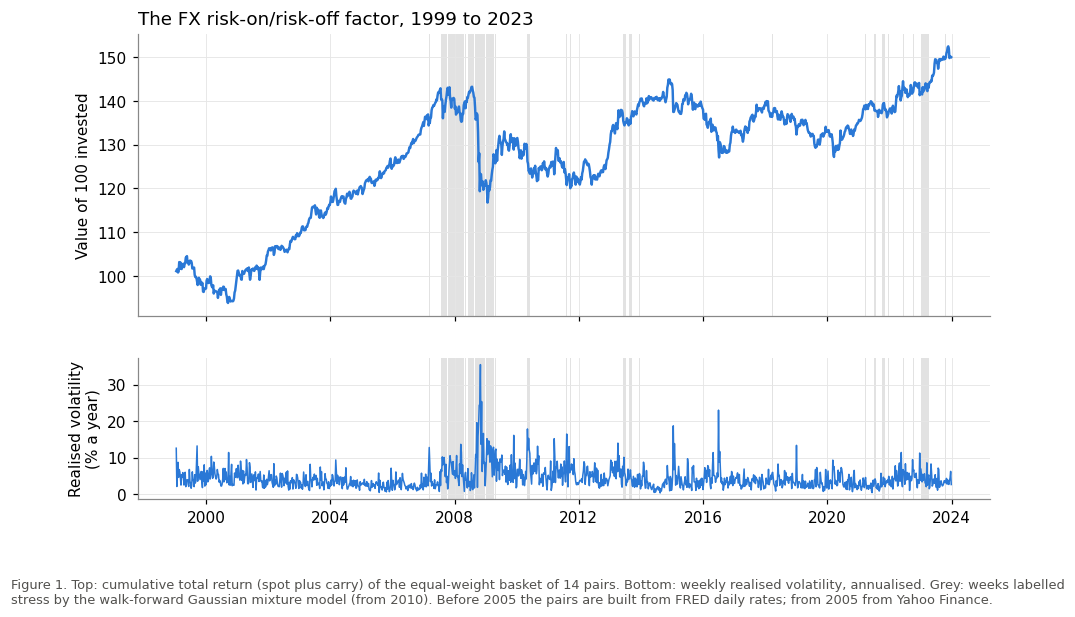

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})
growth = 100 * (1 + weekly["factor"]).cumprod()
ax1.plot(growth.index, growth, color=COLORS[0])
ax2.plot(weekly.index, weekly["rv"] * 100, color=COLORS[0], linewidth=1)

# Shade the weeks the regime model labelled as stress (available in the test years)
stress = regimes["stress_gmm"].astype(bool)
for ax in (ax1, ax2):
    blocks = (stress != stress.shift()).cumsum()
    for _, b in stress[stress].groupby(blocks[stress]):
        ax.axvspan(b.index[0], b.index[-1], color="#d0d0d0", alpha=0.6, linewidth=0)

ax1.set_ylabel("Value of 100 invested")
ax1.set_title(f"The FX risk-on/risk-off factor, {weekly.index[0].year} to {helpers.LAST_TEST_YEAR}", loc="left")
ax2.set_ylabel("Realised volatility\n(% a year)")
save(fig, "fig1_factor",
     "Figure 1. Top: cumulative total return (spot plus carry) of the equal-weight basket of 14 pairs. "
     "Bottom: weekly realised volatility, annualised. Grey: weeks labelled stress by the "
     f"walk-forward Gaussian mixture model (from {helpers.FIRST_TEST_YEAR}). Before 2005 the pairs are "
     "built from FRED daily rates; from 2005 from Yahoo Finance.")

## 3. Figure 2: PCA

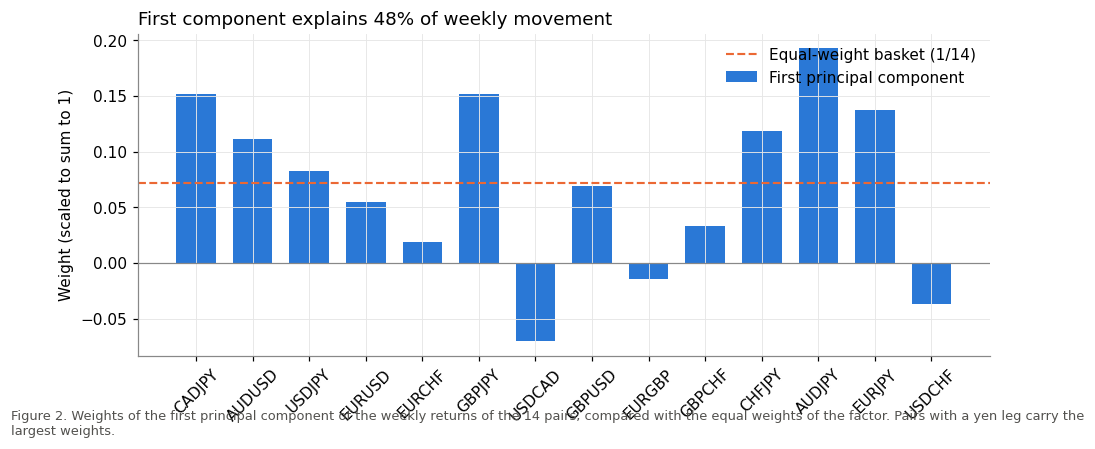

In [ ]:
w = pca["pc1_weight"] / pca["pc1_weight"].sum()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(w.index, w, color=COLORS[0], width=0.7, label="First principal component")
ax.axhline(1 / 14, color=COLORS[1], linestyle="--", linewidth=1.4, label="Equal-weight basket (1/14)")
ax.axhline(0, color="#888888", linewidth=0.8)
ax.set_ylabel("Weight (scaled to sum to 1)")
ax.set_title(f"First component explains {pca['variance_share'].iloc[0]:.0%} of weekly movement",
             loc="left")
ax.legend(loc="upper right")
plt.xticks(rotation=45)
save(fig, "fig2_pca",
     "Figure 2. Weights of the first principal component of the weekly returns of the 14 pairs, "
     "compared with the equal weights of the factor. Pairs with a yen leg carry the largest weights.")

## 4. Figure 3: volatility forecasts

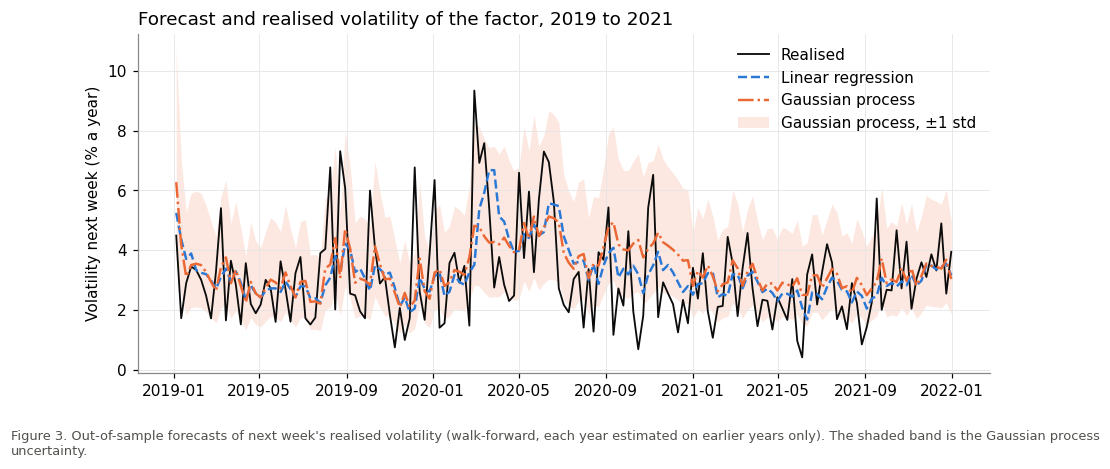

In [ ]:
part = fc.loc["2019":"2021"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(part.index, np.exp(part["realised"]) * 100, color="#0b0b0b", linewidth=1.2, label="Realised")
ax.plot(part.index, np.exp(part["regression"]) * 100, color=COLORS[0], linestyle="--", label="Linear regression")
ax.plot(part.index, np.exp(part["gp"]) * 100, color=COLORS[1], linestyle="-.", label="Gaussian process")
ax.fill_between(part.index, np.exp(part["gp"] - part["gp_std"]) * 100,
                np.exp(part["gp"] + part["gp_std"]) * 100, color=COLORS[1], alpha=0.15,
                linewidth=0, label="Gaussian process, ±1 std")
ax.set_ylabel("Volatility next week (% a year)")
ax.set_title("Forecast and realised volatility of the factor, 2019 to 2021", loc="left")
ax.legend(loc="upper right")
save(fig, "fig3_vol_forecast",
     "Figure 3. Out-of-sample forecasts of next week's realised volatility (walk-forward, each "
     "year estimated on earlier years only). The shaded band is the Gaussian process uncertainty.")

## 5. Figures 4 and 5: the portfolios

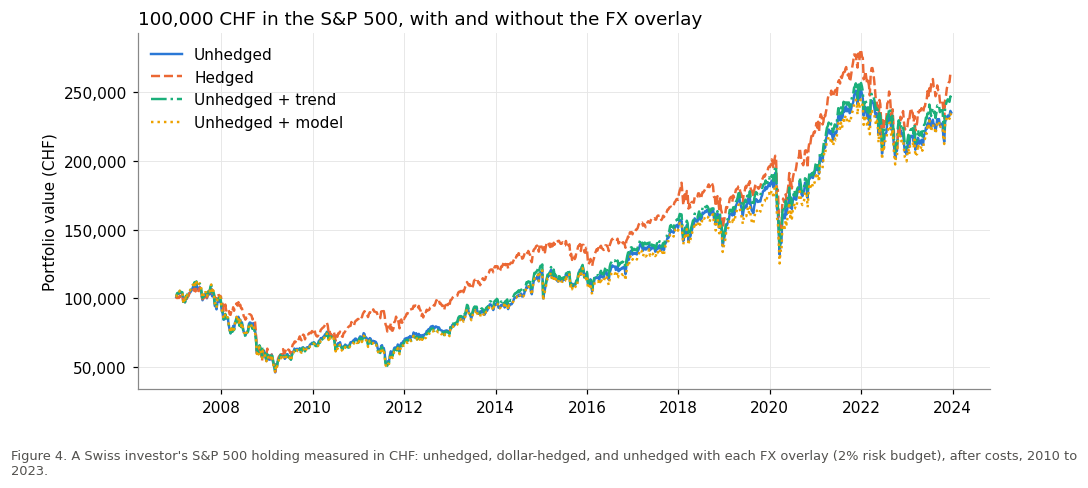

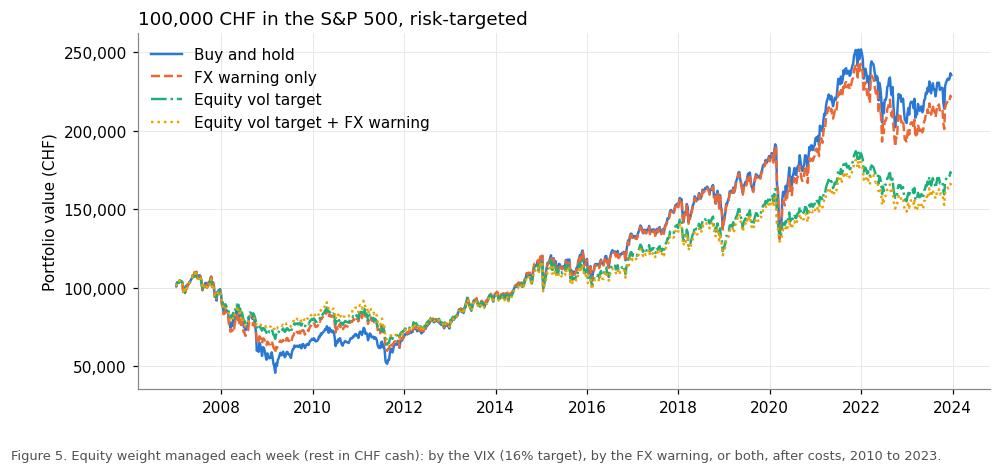

In [ ]:
def growth_chart(df, names, title, file, caption):
    fig, ax = plt.subplots(figsize=(10, 4.2))
    for i, n in enumerate(names):
        value = 100_000 * (1 + df[n]).cumprod()
        ax.plot(value.index, value, color=COLORS[i], linestyle=STYLES[i], label=n)
    ax.set_ylabel("Portfolio value (CHF)")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.set_title(title, loc="left")
    ax.legend(loc="upper left")
    save(fig, file, caption)

growth_chart(returns, port_names, "100,000 CHF in the S&P 500, with and without the FX overlay",
             "fig4_portfolios",
             "Figure 4. A Swiss investor's S&P 500 holding measured in CHF: unhedged, dollar-hedged, and "
             "unhedged with each FX overlay (2% risk budget), after costs, " + f"{helpers.FIRST_TEST_YEAR} to "
             f"{helpers.LAST_TEST_YEAR}.")
growth_chart(returns, rt_names, "100,000 CHF in the S&P 500, risk-targeted", "fig5_risk_targeting",
             "Figure 5. Equity weight managed each week (rest in CHF cash): by the VIX (16% target), "
             "by the FX warning, or both, after costs, " + f"{helpers.FIRST_TEST_YEAR} to {helpers.LAST_TEST_YEAR}.")

## 6. Table 1: the direction model (bagging)

In [ ]:
# Is the test accuracy different from a coin flip? Binomial test on all test weeks.
correct = int(round((bag["test_acc"] * bag["n_test"]).sum()))
n_weeks = int(bag["n_test"].sum())
binom = stats.binomtest(correct, n_weeks, 0.5)
test_accuracy = correct / n_weeks

t1 = bag.set_index("year").round(3)
save_table(t1, "table1_bagging_by_year")
print(f"\nTest accuracy {test_accuracy:.3f} on {n_weeks} weeks; binomial test vs 50%: p = {binom.pvalue:.3f}")
print(f"Average train accuracy {bag['train_acc'].mean():.3f} vs test {bag['test_acc'].mean():.3f}")
print("\nConfusion matrix (rows actual, columns predicted; 1 = up):")
print(bag_conf.to_string())
print("\nWhat the last model relied on (feature importance):")
print(bag_imp.round(3).to_string())

      train_acc  test_acc  n_test
year                             
2010      0.620     0.453      53
2011      0.812     0.365      52
2012      0.696     0.442      52
2013      0.684     0.500      52
2014      0.773     0.500      52
2015      0.596     0.500      52
2016      0.600     0.472      53
2017      0.770     0.519      52
2018      0.656     0.481      52
2019      0.763     0.558      52
2020      0.750     0.577      52
2021      0.733     0.547      53
2022      0.637     0.538      52
2023      0.588     0.549      51

Test accuracy 0.500 on 730 weeks; binomial test vs 50%: p = 1.000
Average train accuracy 0.691 vs test 0.500

Confusion matrix (rows actual, columns predicted; 1 = up):
         0    1
actual         
0       75  279
1       86  290

What the last model relied on (feature importance):
ret_52w          0.289
vix_change_4w    0.158
ret_1w           0.154
ret_4w           0.121
carry            0.116
ret_13w          0.102
vix              0.060


## 7. Table 2: volatility forecast accuracy and Diebold-Mariano tests

In [ ]:
def newey_west_mean(series, lags=4):
    # Mean of a series with a Newey-West t-stat (robust to autocorrelation)
    res = sm.OLS(series.values, np.ones(len(series))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return res.params[0], res.tvalues[0], res.pvalues[0]

# Diebold-Mariano: is the model's squared forecast error significantly smaller than naive's?
# Positive difference = the model is better.
err = fc[["naive", "regression", "garch", "gp"]].sub(fc["realised"], axis=0) ** 2
rows = {}
for m in ["regression", "garch", "gp"]:
    _, t, p = newey_west_mean(err["naive"] - err[m])
    rows[m] = {"MSE": err[m].mean(), "R2 vs naive": 1 - err[m].mean() / err["naive"].mean(),
               "DM t-stat vs naive": t, "p-value": p}
rows["naive"] = {"MSE": err["naive"].mean(), "R2 vs naive": 0.0}
_, t, p = newey_west_mean(err["garch"] - err["regression"])
t2 = pd.DataFrame(rows).T.loc[["naive", "regression", "garch", "gp"]].round(3)
save_table(t2, "table2_vol_forecasts")
print(f"\nRegression vs GARCH: DM t-stat {t:.2f}, p = {p:.3f}")

              MSE  R2 vs naive  DM t-stat vs naive  p-value
naive       0.425        0.000                 NaN      NaN
regression  0.277        0.349               9.916      0.0
garch       0.330        0.223               5.782      0.0
gp          0.338        0.204               3.487      0.0

Regression vs GARCH: DM t-stat 4.83, p = 0.000


## 8. Table 3: crisis table

In [ ]:
crises = {
    "2008 financial crisis": ("2008-09-01", "2009-03-09"),
    "2011 summer (euro crisis)": ("2011-07-01", "2011-09-30"),
    "2015 SNB shock (January)": ("2015-01-01", "2015-01-31"),
    "2018 Q4 selloff": ("2018-10-01", "2018-12-31"),
    "2020 Covid crash (Feb-Mar)": ("2020-02-15", "2020-03-31"),
    "2022 full year": ("2022-01-01", "2022-12-31"),
    "2024 August yen carry unwind": ("2024-07-15", "2024-08-16"),
    "2025 April tariff shock": ("2025-03-24", "2025-04-18"),
}
crises = {k: v for k, v in crises.items() if int(v[1][:4]) <= helpers.LAST_TEST_YEAR}
names = port_names + rt_names[2:]
t3 = pd.DataFrame({c: ((1 + returns.loc[a:b, names]).prod() - 1) * 100_000
                   for c, (a, b) in crises.items()}).T.round(0)
print("Change in value of a 100,000 CHF portfolio, in CHF:")
save_table(t3, "table3_crises")

Change in value of a 100,000 CHF portfolio, in CHF:
                            Unhedged   Hedged  Unhedged + trend  Unhedged + model  Equity vol target  Equity vol target + FX warning
2008 financial crisis       -43666.0 -46983.0          -41342.0          -43023.0           -19258.0                        -10230.0
2011 summer (euro crisis)    -4422.0 -10820.0           -3824.0           -5391.0            -6985.0                        -10043.0
2015 SNB shock (January)    -10541.0  -4498.0          -12577.0          -12081.0            -9956.0                         -9972.0
2018 Q4 selloff             -13830.0 -15355.0          -13090.0          -14432.0           -13457.0                        -13457.0
2020 Covid crash (Feb-Mar)  -26135.0 -25034.0          -25389.0          -26272.0           -17455.0                        -18173.0
2022 full year              -18636.0 -20991.0          -18530.0          -18464.0           -16490.0                        -17640.0


## 9. Table 4: performance of every strategy

In [ ]:
# Turnover = average yearly sum of position changes (0 for passive portfolios)
positions = {
    "Unhedged + trend": overlay["pos_trend"], "Trend overlay alone": overlay["pos_trend"],
    "Unhedged + model": overlay["pos_model"], "Model overlay alone": overlay["pos_model"],
    "Vol-managed carry": carry["pos_carry"],
}
for n in rt_names:
    positions[n] = rt[f"w_{n}"]
years = len(returns) / 52

t4 = pd.DataFrame({
    "return p.a.": (1 + returns).prod() ** (52 / len(returns)) - 1,
    "volatility": returns.std() * np.sqrt(52),
    "Sharpe": returns.apply(helpers.sharpe_ratio),
    "worst loss": returns.apply(helpers.max_drawdown),
    "turnover p.a.": pd.Series({n: positions[n].diff().abs().sum() / years for n in positions}),
}).loc[returns.columns].round(3)
t4["turnover p.a."] = t4["turnover p.a."].fillna(0)   # passive strategies never trade
save_table(t4, "table4_performance")

                                return p.a.  volatility  Sharpe  worst loss  turnover p.a.
Unhedged                              0.052       0.201   0.352      -0.584          0.000
Hedged                                0.059       0.185   0.404      -0.571          0.000
Unhedged + trend                      0.054       0.200   0.366      -0.586          1.878
Unhedged + model                      0.051       0.206   0.346      -0.595          2.881
Buy and hold                          0.052       0.201   0.352      -0.584          0.000
FX warning only                       0.048       0.181   0.349      -0.469          0.998
Equity vol target                     0.033       0.144   0.296      -0.417          2.729
Equity vol target + FX warning        0.030       0.140   0.282      -0.386          3.185
Trend overlay alone                   0.002       0.023   0.101      -0.071          1.878
Model overlay alone                   0.000       0.016   0.026      -0.068          2.881

In [ ]:
# Tail risk: what a risk manager looks at beyond the Sharpe ratio
def longest_drawdown_weeks(r):
    wealth = (1 + r).cumprod()
    under = wealth < wealth.cummax()
    runs = under.groupby((~under).cumsum()).sum()
    return int(runs.max())

down = sp_chf < 0
rows = {}
for n in returns.columns:
    r = returns[n]
    worst5 = r[r <= r.quantile(0.05)]
    rows[n] = {"skewness": r.skew(), "worst week": r.min(),
               "expected shortfall 5%": worst5.mean(),
               "downside beta": np.polyfit(sp_chf[down], r[down], 1)[0],
               "longest drawdown (weeks)": longest_drawdown_weeks(r)}
t4b = pd.DataFrame(rows).T.round(3)
save_table(t4b, "table4b_tail_risk")

                                skewness  worst week  expected shortfall 5%  downside beta  longest drawdown (weeks)
Unhedged                          -0.643      -0.171                 -0.068          1.000                     384.0
Hedged                            -0.604      -0.182                 -0.062          0.783                     302.0
Unhedged + trend                  -0.698      -0.186                 -0.068          0.988                     378.0
Unhedged + model                  -0.676      -0.183                 -0.069          1.022                     385.0
Buy and hold                      -0.643      -0.171                 -0.068          1.000                     384.0
FX warning only                   -0.876      -0.171                 -0.063          0.871                     384.0
Equity vol target                 -1.226      -0.156                 -0.050          0.656                     384.0
Equity vol target + FX warning    -1.331      -0.156            

## 10. Table 5: statistical evidence

In [ ]:
# (a) Each strategy: is its mean return different from zero, and how does it move with
# the investor's equities (beta)? Newey-West standard errors, 4 lags.
rows = {}
for n in returns.columns:
    r = returns[n]
    mean, t, p = newey_west_mean(r)
    beta_fit = sm.OLS(r.values, sm.add_constant(sp_chf.values)).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
    rows[n] = {"mean p.a.": mean * 52, "t-stat": t, "p-value": p,
               "beta to S&P (CHF)": beta_fit.params[1], "beta t-stat": beta_fit.tvalues[1]}
    # The S&P against itself has beta 1 by definition: no test to report
    if np.allclose(r.values, sp_chf.values):
        rows[n]["beta t-stat"] = np.nan
t5a = pd.DataFrame(rows).T.round(3)
save_table(t5a, "table5a_returns_and_betas")

                                mean p.a.  t-stat  p-value  beta to S&P (CHF)  beta t-stat
Unhedged                            0.071   1.591    0.112              1.000          NaN
Hedged                              0.075   1.794    0.073              0.793       16.563
Unhedged + trend                    0.073   1.664    0.096              0.987       99.557
Unhedged + model                    0.071   1.567    0.117              1.020      185.045
Buy and hold                        0.071   1.591    0.112              1.000          NaN
FX warning only                     0.063   1.541    0.123              0.875       26.155
Equity vol target                   0.043   1.325    0.185              0.670       18.487
Equity vol target + FX warning      0.039   1.255    0.209              0.624       13.800
Trend overlay alone                 0.002   0.433    0.665             -0.013       -1.354
Model overlay alone                 0.000   0.111    0.912              0.020        3.568

In [ ]:
# (b) Is each strategy's Sharpe ratio better than its benchmark's by more than luck?
# Block bootstrap: resample 13-week blocks (keeping the time structure) 5,000 times,
# the same weeks for both series. p-value = share of draws where the difference is <= 0.
def block_bootstrap_sharpe_diff(a, b, block=13, draws=5000, seed=helpers.SEED):
    rng = np.random.default_rng(seed)
    a, b = a.values, b.values
    n = len(a)
    diffs = np.empty(draws)
    for i in range(draws):
        starts = rng.integers(0, n - block, size=n // block + 1)
        idx = np.concatenate([np.arange(s, s + block) for s in starts])[:n]
        sa = a[idx].mean() / a[idx].std() * np.sqrt(52)
        sb = b[idx].mean() / b[idx].std() * np.sqrt(52)
        diffs[i] = sa - sb
    return diffs

pairs = [
    ("Unhedged + trend", "Unhedged"),
    ("Unhedged + model", "Unhedged"),
    ("Equity vol target", "Buy and hold"),
    ("Equity vol target + FX warning", "Equity vol target"),
    ("Vol-managed carry", "Plain carry"),
]
rows = {}
for s, b in pairs:
    d = block_bootstrap_sharpe_diff(returns[s], returns[b])
    rows[f"{s} vs {b}"] = {
        "Sharpe difference": helpers.sharpe_ratio(returns[s]) - helpers.sharpe_ratio(returns[b]),
        "95% interval low": np.percentile(d, 2.5), "95% interval high": np.percentile(d, 97.5),
        "p-value (one-sided)": (d <= 0).mean(),
        # Smallest difference this sample could detect (80% power, 5% level)
        "detectable difference": 2.8 * d.std()}
t5b = pd.DataFrame(rows).T.round(3)
save_table(t5b, "table5b_sharpe_bootstrap")

                                                     Sharpe difference  95% interval low  95% interval high  p-value (one-sided)  detectable difference
Unhedged + trend vs Unhedged                                     0.014            -0.037              0.063                0.307                  0.072
Unhedged + model vs Unhedged                                    -0.006            -0.041              0.029                0.645                  0.049
Equity vol target vs Buy and hold                               -0.056            -0.201              0.091                0.804                  0.207
Equity vol target + FX warning vs Equity vol target             -0.014            -0.084              0.063                0.669                  0.104
Vol-managed carry vs Plain carry                                -0.042            -0.218              0.106                0.772                  0.232


In [ ]:
# (c) In the worst 16% of quarters for the benchmark, did the strategy lose less?
# Paired difference per quarter, with a t-test. Caveat: few quarters, so low power.
quarterly = (1 + returns).resample("QE").prod() - 1
rows = {}
for s, b in pairs[:4]:
    worst = quarterly[b] <= quarterly[b].quantile(0.16)
    diff = (quarterly.loc[worst, s] - quarterly.loc[worst, b]) * 100_000
    t, p = stats.ttest_1samp(diff, 0)
    rows[f"{s} vs {b}"] = {"quarters": int(worst.sum()), "avg CHF saved per quarter": diff.mean(),
                           "t-stat": t, "p-value": p}
t5c = pd.DataFrame(rows).T.round(3)
save_table(t5c, "table5c_worst_quarters")
print("\nNote: several strategies were tested; single p-values below 0.05 should be read with care.")

                                                     quarters  avg CHF saved per quarter  t-stat  p-value
Unhedged + trend vs Unhedged                             11.0                    567.889   1.309    0.220
Unhedged + model vs Unhedged                             11.0                    -54.463  -0.202    0.844
Equity vol target vs Buy and hold                        11.0                   3533.146   2.116    0.060
Equity vol target + FX warning vs Equity vol target      11.0                    -91.903  -0.137    0.894

Note: several strategies were tested; single p-values below 0.05 should be read with care.


## 11. Appendix: robustness and currency dendrogram

In [ ]:
# Sharpe ratio of the main strategies under each variation (PLAN.md 5g).
base = {
    "Unhedged + trend": returns["Unhedged + trend"],
    "Unhedged + model": returns["Unhedged + model"],
    "Equity vol target + FX warning": returns["Equity vol target + FX warning"],
    "Vol-managed carry": returns["Vol-managed carry"],
}
pos_for = {"Unhedged + trend": (overlay["pos_trend"], helpers.COST_BP),
           "Unhedged + model": (overlay["pos_model"], helpers.COST_BP),
           "Equity vol target + FX warning": (rt["w_Equity vol target + FX warning"], 5),
           "Vol-managed carry": (carry["pos_carry"], helpers.COST_BP)}

robust = {"Base case": {k: helpers.sharpe_ratio(v) for k, v in base.items()}}

# Costs doubled: subtract the same cost a second time
robust["Costs doubled"] = {k: helpers.sharpe_ratio(v - pos_for[k][1] / 1e4 * pos_for[k][0].diff().abs().fillna(0))
                           for k, v in base.items()}

# 2022 left out
robust["Without 2022"] = {k: helpers.sharpe_ratio(v[v.index.year != 2022]) for k, v in base.items()}

# Model overlay: flat in stress weeks instead of following the trend
factor = weekly["factor"].loc[overlay.index]
pos_flat = overlay["pos_model"].where(~overlay["stress"].astype(bool), 0.0)
ov_flat = (pos_flat.shift(1) * factor - helpers.COST_BP / 1e4 * pos_flat.diff().abs().fillna(0)).fillna(0)
robust["Flat in stress (model)"] = {"Unhedged + model": helpers.sharpe_ratio(returns["Unhedged"] + ov_flat)}

# Price-error rule switched off: rebuild the factor from the raw closes without that rule,
# then recompute the trend overlay exactly as before
def load_close(name):
    df = pd.read_csv(f"{helpers.RAW}/{name}.csv", header=[0, 1], index_col=0, parse_dates=True)
    return df["Close"].iloc[:, 0]

with open(f"{helpers.RAW}/download_date.txt") as f:
    download_date = pd.Timestamp(f.read().strip())
closes = pd.DataFrame({p: load_close(p) for p in helpers.ALL_PAIRS})
closes = closes[closes.index < download_date]
missing = closes["AUDUSD"].isna()
closes.loc[missing, "AUDUSD"] = (closes["AUDJPY"] / closes["USDJPY"])[missing]
closes = closes.reindex(pd.bdate_range(closes.index.min(), closes.index.max())).ffill().dropna()
raw_factor = (closes.resample("W-FRI").last().pct_change().mean(axis=1)
              + weekly["carry"] / 100 / 52).reindex(weekly.index)
trend_raw = np.sign((1 + raw_factor).rolling(52).apply(np.prod, raw=True) - 1) * 0.40
trend_raw = trend_raw.loc[overlay.index]
ov_raw = (trend_raw.shift(1) * raw_factor.loc[overlay.index]
          - helpers.COST_BP / 1e4 * trend_raw.diff().abs().fillna(0)).fillna(0)
robust["Price-error rule off (trend)"] = {"Unhedged + trend": helpers.sharpe_ratio(returns["Unhedged"] + ov_raw)}

t6 = pd.DataFrame(robust).T[list(base)].round(3)
print("Sharpe ratio under each variation (blank = not applicable):")
save_table(t6, "tableA1_robustness")

Sharpe ratio under each variation (blank = not applicable):
                              Unhedged + trend  Unhedged + model  Equity vol target + FX warning  Vol-managed carry
Base case                                0.366             0.346                           0.282              0.095
Costs doubled                            0.363             0.342                           0.270              0.066
Without 2022                             0.447             0.424                           0.380              0.073
Flat in stress (model)                     NaN             0.346                             NaN                NaN
Price-error rule off (trend)             0.366               NaN                             NaN                NaN


In [ ]:
# Trend lookback: 13, 26 and 52 weeks, all shown, none chosen (52 is the main specification)
factor_all = weekly["factor"]
rows = {}
for L in (13, 26, 52):
    pos = np.sign((1 + factor_all).rolling(L).apply(np.prod, raw=True) - 1) * 0.40
    pos = pos.loc[overlay.index]
    ov = (pos.shift(1) * factor_all.loc[overlay.index]
          - helpers.COST_BP / 1e4 * pos.diff().abs().fillna(0)).fillna(0)
    port = returns["Unhedged"] + ov
    q = (1 + pd.concat([port, returns["Unhedged"]], axis=1)).resample("QE").prod() - 1
    worst = q.iloc[:, 1] <= q.iloc[:, 1].quantile(0.16)
    rows[f"{L} weeks"] = {"trend alone, Sharpe": helpers.sharpe_ratio(ov),
                          "portfolio Sharpe": helpers.sharpe_ratio(port),
                          "CHF saved per worst quarter": (q.iloc[:, 0] - q.iloc[:, 1])[worst].mean() * 100_000}
tA2 = pd.DataFrame(rows).T.round(3)
save_table(tA2, "tableA2_lookbacks")

          trend alone, Sharpe  portfolio Sharpe  CHF saved per worst quarter
13 weeks                0.027             0.358                      390.740
26 weeks               -0.231             0.326                      215.047
52 weeks                0.101             0.366                      567.889


In [ ]:
# The years before the test window (2000-2006): the trend rule needs no training, so it can
# be shown there too, including the dot-com bear market. Same rule, same 0.40 exposure.
early = weekly.loc[:str(helpers.FIRST_TEST_YEAR - 1)]
pos = np.sign((1 + early["factor"]).rolling(52).apply(np.prod, raw=True) - 1) * 0.40
ov = (pos.shift(1) * early["factor"] - helpers.COST_BP / 1e4 * pos.diff().abs().fillna(0)).dropna()
sp_early = ((1 + early["sp500_ret"]) * (1 + early["ret_USDCHF"]) - 1).loc[ov.index]
early_df = pd.DataFrame({"Unhedged": sp_early, "Unhedged + trend": sp_early + ov, "Trend overlay alone": ov})

periods = {"Dot-com bear market": ("2000-03-24", "2002-10-09"), "2003-2006 recovery": ("2003-01-01", "2006-12-31")}
tA3 = pd.DataFrame({p: ((1 + early_df.loc[a:b]).prod() - 1) * 100_000 for p, (a, b) in periods.items()}).T.round(0)
tA3.loc["Sharpe 2000-2006"] = early_df.apply(helpers.sharpe_ratio).round(3)
print("Change of 100,000 CHF (CHF), and Sharpe ratio, before the test window:")
save_table(tA3, "tableA3_before_test_window")

Change of 100,000 CHF (CHF), and Sharpe ratio, before the test window:
                      Unhedged  Unhedged + trend  Trend overlay alone
Dot-com bear market -51014.000         -49999.00             2284.000
2003-2006 recovery   41556.000          54453.00             9027.000
Sharpe 2000-2006        -0.174             -0.13                0.437


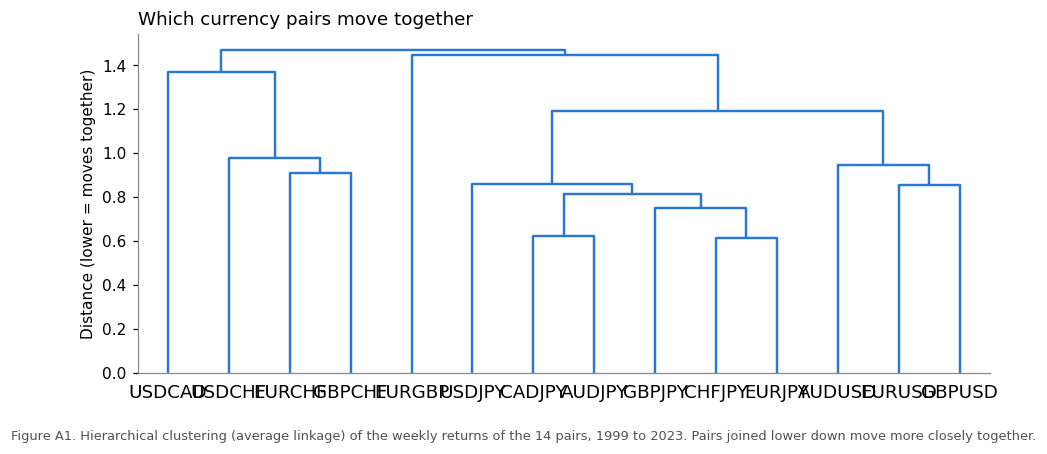

In [ ]:
# Which currency pairs move together? Distance = sqrt(2 x (1 - correlation)).
corr = weekly[[f"ret_{p}" for p in helpers.ALL_PAIRS]].corr()
corr.index = corr.columns = helpers.ALL_PAIRS
dist = np.sqrt(2 * (1 - corr.clip(-1, 1)))
link = linkage(squareform(dist.values, checks=False), method="average")

fig, ax = plt.subplots(figsize=(10, 4))
dendrogram(link, labels=corr.index.tolist(), ax=ax, color_threshold=0,
           above_threshold_color=COLORS[0])
ax.set_ylabel("Distance (lower = moves together)")
ax.set_title("Which currency pairs move together", loc="left")
ax.grid(False)
save(fig, "figA1_dendrogram",
     "Figure A1. Hierarchical clustering (average linkage) of the weekly returns of the 14 pairs, "
     f"{weekly.index[0].year} to {helpers.LAST_TEST_YEAR}. Pairs joined lower down move more closely together.")

## 12. Risk management: VaR backtest and risk budgeting

In [ ]:
# Table 6: does the forecast VaR get breached as often as it should, without clustering?
var_bt = pd.read_csv(f"{P}/var_backtest.csv", index_col=[0, 1])
save_table(var_bt, "table6_var_backtest")

                  breach rate  expected  Kupiec p  Christoffersen p
level model                                                        
95%   fixed             0.067      0.05     0.031             0.578
      naive             0.107      0.05     0.000             0.427
      regression        0.088      0.05     0.000             0.958
      garch             0.050      0.05     0.963             0.242
      gp                0.086      0.05     0.000             0.498
99%   fixed             0.033      0.01     0.000             0.328
      naive             0.058      0.01     0.000             0.531
      regression        0.037      0.01     0.000             0.506
      garch             0.026      0.01     0.000             0.625
      gp                0.041      0.01     0.000             0.661


            average risk  std of quarterly risk  share of quarters 1%-3%  highest quarter
fixed             0.0228                 0.0131                   0.8088           0.1023
naive             0.0303                 0.0102                   0.5735           0.0639
regression        0.0258                 0.0069                   0.8088           0.0478
gp                0.0259                 0.0089                   0.7500           0.0598


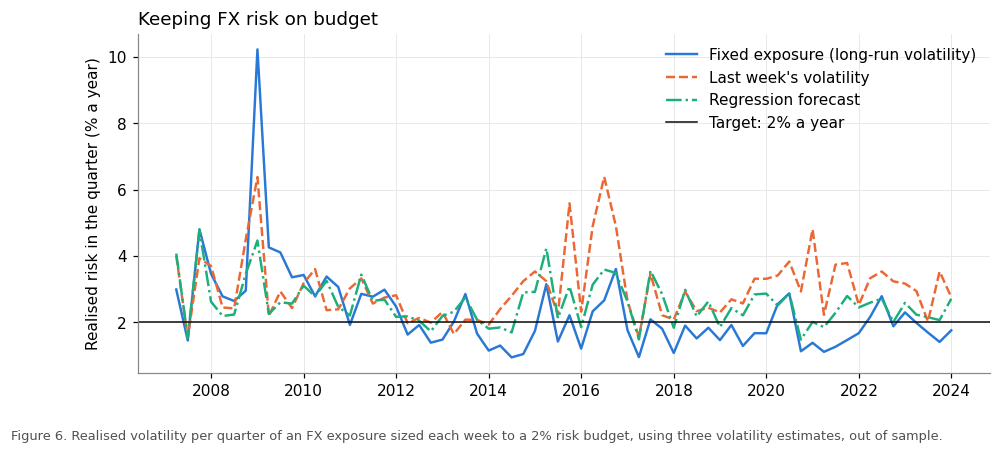

In [ ]:
# Table 7 and figure 6: keeping the FX exposure at a 2% risk budget
budget = pd.read_csv(f"{P}/risk_budget.csv", index_col=0)
save_table(budget, "table7_risk_budget")

qrisk = pd.read_csv(f"{P}/risk_budget_quarterly.csv", index_col=0, parse_dates=True)
fig, ax = plt.subplots(figsize=(10, 4))
for i, (m, label) in enumerate([("fixed", "Fixed exposure (long-run volatility)"),
                                ("naive", "Last week's volatility"),
                                ("regression", "Regression forecast")]):
    ax.plot(qrisk.index, qrisk[m] * 100, color=COLORS[i], linestyle=STYLES[i], label=label)
ax.axhline(2, color="#0b0b0b", linewidth=1, label="Target: 2% a year")
ax.set_ylabel("Realised risk in the quarter (% a year)")
ax.set_title("Keeping FX risk on budget", loc="left")
ax.legend(loc="upper right")
save(fig, "fig6_risk_budget",
     "Figure 6. Realised volatility per quarter of an FX exposure sized each week to a 2% risk "
     "budget, using three volatility estimates, out of sample.")

## 13. Table 0: simple vs machine learning

In [ ]:
# The research question in one table: in each job, does machine learning beat the simple
# alternative? Built only from the results above. 'Winner' is ML only when ML is better AND
# the difference is significant at 5%; otherwise the simple approach is kept.

# Direction: trend rule vs bagging, both run on the factor alone (notebook 03)
dir_ret = pd.read_csv(f"{P}/positions_test_years.csv", index_col=0, parse_dates=True)
d = block_bootstrap_sharpe_diff(dir_ret["ret_model"], dir_ret["ret_rule"])
p_dir = (d <= 0).mean()

def winner(ml_better, p):
    if ml_better and p < 0.05:
        return "Machine learning"
    return "Simple" if not ml_better else "Tie (not significant)"

best_ml = t2.loc[["regression", "garch", "gp"], "R2 vs naive"].idxmax()
rows = [
    {"Job": "1. Predict next week's direction",
     "Simple": f"Trend rule, Sharpe {helpers.sharpe_ratio(dir_ret['ret_rule']):.2f}",
     "Machine learning": f"Bagging, Sharpe {helpers.sharpe_ratio(dir_ret['ret_model']):.2f}, accuracy {test_accuracy:.1%}",
     "Evidence": f"Accuracy vs 50%: p = {binom.pvalue:.2f}; Sharpe difference p = {p_dir:.2f}",
     "Winner": winner(False, p_dir)},
    {"Job": "2. Predict next week's volatility",
     "Simple": "Naive (same as last week)",
     "Machine learning": f"Regression R2 {t2.loc['regression', 'R2 vs naive']:.2f}, GP {t2.loc['gp', 'R2 vs naive']:.2f}",
     "Evidence": f"Diebold-Mariano vs naive: t = {t2.loc['regression', 'DM t-stat vs naive']:.1f} (regression), "
                 f"{t2.loc['gp', 'DM t-stat vs naive']:.1f} (GP)",
     "Winner": winner(True, t2.loc[best_ml, "p-value"]) + f" ({best_ml})"},
    {"Job": "3a. Trade the factor as an overlay",
     "Simple": f"Trend overlay, portfolio Sharpe {t4.loc['Unhedged + trend', 'Sharpe']:.3f}",
     "Machine learning": f"Model overlay, portfolio Sharpe {t4.loc['Unhedged + model', 'Sharpe']:.3f}",
     "Evidence": f"Model vs unhedged p = {t5b.loc['Unhedged + model vs Unhedged', 'p-value (one-sided)']:.2f}; "
                 f"trend vs unhedged p = {t5b.loc['Unhedged + trend vs Unhedged', 'p-value (one-sided)']:.2f}",
     "Winner": winner(t4.loc["Unhedged + model", "Sharpe"] > t4.loc["Unhedged + trend", "Sharpe"],
                      t5b.loc["Unhedged + model vs Unhedged", "p-value (one-sided)"])},
    {"Job": "3b. Trade the factor on its own (carry)",
     "Simple": f"Plain carry, Sharpe {t4.loc['Plain carry', 'Sharpe']:.2f}",
     "Machine learning": f"Vol-managed carry, Sharpe {t4.loc['Vol-managed carry', 'Sharpe']:.2f}",
     "Evidence": f"p = {t5b.loc['Vol-managed carry vs Plain carry', 'p-value (one-sided)']:.2f}",
     "Winner": winner(t4.loc["Vol-managed carry", "Sharpe"] > t4.loc["Plain carry", "Sharpe"],
                      t5b.loc["Vol-managed carry vs Plain carry", "p-value (one-sided)"])},
    {"Job": "4. Protect in the worst equity quarters",
     "Simple": f"Trend overlay saves {t5c.loc['Unhedged + trend vs Unhedged', 'avg CHF saved per quarter']:.0f} CHF a quarter",
     "Machine learning": f"Model overlay saves {t5c.loc['Unhedged + model vs Unhedged', 'avg CHF saved per quarter']:.0f} CHF; "
                         f"FX warning adds {t5c.loc['Equity vol target + FX warning vs Equity vol target', 'avg CHF saved per quarter']:.0f} CHF",
     "Evidence": f"p = {t5c.loc['Unhedged + trend vs Unhedged', 'p-value']:.2f} (trend), "
                 f"{t5c.loc['Unhedged + model vs Unhedged', 'p-value']:.2f} (model)",
     "Winner": "Neither significant"},
    {"Job": "5. Keep FX risk on a 2% budget",
     "Simple": f"Fixed exposure: quarterly risk varies by {budget.loc['fixed', 'std of quarterly risk']:.2%}, "
               f"worst quarter {budget.loc['fixed', 'highest quarter']:.1%}",
     "Machine learning": f"Regression forecast: varies by {budget.loc['regression', 'std of quarterly risk']:.2%}, "
                         f"worst quarter {budget.loc['regression', 'highest quarter']:.1%}",
     "Evidence": f"95% VaR breach rate: regression {var_bt.loc[('95%', 'regression'), 'breach rate']:.1%}, "
                 f"GARCH {var_bt.loc[('95%', 'garch'), 'breach rate']:.1%} (target 5%)",
     # ML wins if its quarterly risk is more stable than both the fixed and the naive exposure
     "Winner": "Machine learning (regression)"
               if budget.loc["regression", "std of quarterly risk"] < budget.loc[["fixed", "naive"], "std of quarterly risk"].min()
               else "Simple"},
]
t0 = pd.DataFrame(rows).set_index("Job")
pd.set_option("display.max_colwidth", 80)
save_table(t0, "table0_simple_vs_ml")

                                                                                                      Simple                                          Machine learning                                                      Evidence                         Winner
Job                                                                                                                                                                                                                                                                
1. Predict next week's direction                                                     Trend rule, Sharpe 0.18                      Bagging, Sharpe 0.13, accuracy 50.0%         Accuracy vs 50%: p = 1.00; Sharpe difference p = 0.56                         Simple
2. Predict next week's volatility                                                  Naive (same as last week)                               Regression R2 0.35, GP 0.20      Diebold-Mariano vs naive: t = 9.9 (regression), 

## 14. Checks

In [ ]:
expected = ["fig1_factor", "fig2_pca", "fig3_vol_forecast", "fig4_portfolios", "fig5_risk_targeting",
            "fig6_risk_budget", "figA1_dendrogram"]
for f in expected:
    assert os.path.exists(f"{helpers.FIGURES}/{f}.png"), f"Missing figure {f}"
for t in ["table0_simple_vs_ml", "table1_bagging_by_year", "table2_vol_forecasts", "table3_crises", "table4_performance",
          "table5a_returns_and_betas", "table5b_sharpe_bootstrap", "table5c_worst_quarters",
          "tableA1_robustness", "table4b_tail_risk", "tableA2_lookbacks", "tableA3_before_test_window",
          "table6_var_backtest", "table7_risk_budget"]:
    assert os.path.exists(f"{helpers.FIGURES}/{t}.csv"), f"Missing table {t}"

# No holdout data in any result
assert returns.index.max().year <= helpers.LAST_TEST_YEAR, "Holdout data used"
# The base-case Sharpe in the robustness table matches the performance table
assert abs(t6.loc["Base case", "Unhedged + trend"] - t4.loc["Unhedged + trend", "Sharpe"]) < 0.002

print("All checks passed")

All checks passed
